# Nate's scratch notebook — Q1 and Q4


In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display

# Find the team repository
REPO_NAME = "F26-DS2002-Midterm-Repo-Nate-Mohamed-Mouad"

def find_repo_root():
    here = Path.cwd()

    folders = [
        here,
        *here.parents,
        Path("/content") / REPO_NAME
    ]

    for folder in folders:
        if (
                (folder / "CHARTER.md").is_file()
                and (folder / "data" / "walmart_transactions.csv").is_file()
        ):
            return folder

    raise FileNotFoundError(
        "Team repository not found. Open this notebook "
        "from your cloned repo or clone the repo into Colab."
    )


REPO_ROOT = find_repo_root()

def find_data(filename):
    path = REPO_ROOT / "data" / filename

    if not path.is_file():
        raise FileNotFoundError(filename)

    return path


# Load the transaction and store files
raw = pd.read_csv(
    find_data("walmart_transactions.csv"),
    na_values=["NULL", "N/A", "NaN"]
)

stores_raw = pd.read_csv(
    find_data("store_locations.csv"),
    na_values=["NULL", "N/A", "NaN"]
)

print("Original transactions:", len(raw))
print("Store reference rows:", len(stores_raw))


# Standardize store IDs
def clean_store_id(series):
    return (
        series.astype("string")
        .str.strip()
        .str.upper()
        .str.replace(
            r"^FL[-_\s]*(\d+)$",
            r"FL-\1",
            regex=True
        )
    )


# Parse different timestamp formats
def clean_dates(series):
    formats = [
        "%Y-%m-%dT%H:%M:%S",
        "%Y-%m-%d %H:%M:%S",
        "%Y-%m-%d %H:%M",
        "%m/%d/%Y %H:%M",
        "%m/%d/%Y %H:%M:%S",
        "%m-%d-%Y %H:%M:%S",
        "%m-%d-%Y %H:%M",
        "%d-%b-%Y %H:%M",
        "%d-%b-%Y %H:%M:%S"
    ]

    result = pd.Series(
        pd.NaT,
        index=series.index,
        dtype="datetime64[ns]"
    )

    for fmt in formats:
        parsed = pd.to_datetime(
            series,
            format=fmt,
            errors="coerce"
        )

        result = result.fillna(parsed)

    return result


# Standardize category labels
CATEGORY_ALIASES = {
    "Alcoholic Beverages": "Alcohol",
    "Baby Products": "Baby",
    "Breakfast Foods": "Breakfast",
    "Emergency Supplies": "Emergency",
    "Games & Entertainment": "Entertainment",
    "Groceries": "Grocery",
    "Health & Wellness": "Health",
    "Household Essentials": "Household"
}


def clean_category(series):
    return (
        series.astype("string")
        .str.strip()
        .str.title()
        .replace(CATEGORY_ALIASES)
    )


# Main transaction cleaning function
def clean_transactions(df):
    cleaned = df.copy()
    log = []

    # 1. Remove exact duplicate rows
    before = len(cleaned)
    cleaned = cleaned.drop_duplicates().copy()

    log.append({
        "dataset": "transactions",
        "step": "Remove exact duplicates",
        "before": before,
        "after": len(cleaned),
        "affected": before - len(cleaned)
    })

    # Helper for logging steps that do not remove rows
    def log_step(step, affected):
        log.append({
            "dataset": "transactions",
            "step": step,
            "before": len(cleaned),
            "after": len(cleaned),
            "affected": int(affected)
        })

    # 2. Standardize store IDs
    cleaned["store_id_clean"] = clean_store_id(
        cleaned["store_id"]
    )

    changed_stores = (
            cleaned["store_id"].astype("string")
            != cleaned["store_id_clean"]
    ).fillna(False).sum()

    log_step("Standardize store IDs", changed_stores)

    # 3. Parse timestamps
    cleaned["timestamp_clean"] = clean_dates(
        cleaned["timestamp"]
    )

    # Create daily dates for the weather join
    cleaned["date"] = (
        cleaned["timestamp_clean"].dt.normalize()
    )

    log_step(
        "Parse nonmissing timestamps",
        cleaned["timestamp_clean"].notna().sum()
    )

    log_step(
        "Flag missing / unparseable timestamps",
        cleaned["timestamp_clean"].isna().sum()
    )

    log_step(
        "Create daily date keys",
        cleaned["date"].notna().sum()
    )

    # 4. Convert prices into numeric values
    price_text = cleaned["unit_price"].astype("string")

    formatted_prices = price_text.str.contains(
        r"\$|^\s|\s$",
        regex=True,
        na=False
    ).sum()

    cleaned["unit_price_clean"] = pd.to_numeric(
        price_text
        .str.strip()
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

    log_step(
        "Clean formatted unit prices",
        formatted_prices
    )

    log_step(
        "Flag missing/unparseable unit prices",
        cleaned["unit_price_clean"].isna().sum()
    )

    # 5. Convert quantities and flag possible returns
    cleaned["quantity_clean"] = pd.to_numeric(
        cleaned["quantity"],
        errors="coerce"
    )

    cleaned["possible_return"] = (
            cleaned["quantity_clean"] < 0
    )

    log_step(
        "Flag negative quantities",
        cleaned["possible_return"].sum()
    )

    log_step(
        "Flag missing/unparseable quantities",
        cleaned["quantity_clean"].isna().sum()
    )

    # 6. Standardize SKUs
    cleaned["sku_clean"] = (
        cleaned["sku"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    changed_skus = (
            cleaned["sku"].astype("string")
            != cleaned["sku_clean"]
    ).fillna(False).sum()

    log_step(
        "Standardize SKU formatting",
        changed_skus
    )

    # 7. Standardize categories
    cleaned["category_clean"] = clean_category(
        cleaned["category"]
    )

    changed_categories = (
            cleaned["category"].astype("string")
            != cleaned["category_clean"]
    ).fillna(False).sum()

    log_step(
        "Standardize category formatting and aliases",
        changed_categories
    )

    return cleaned, pd.DataFrame(log)


Original transactions: 25562
Store reference rows: 14


In [ ]:
# Run the cleaning function
clean, decision_log = clean_transactions(raw)


# Standardize the store reference data
stores_clean = stores_raw.copy()

stores_clean["store_id_clean"] = clean_store_id(
    stores_clean["store_id"]
)

# Check that store aliases do not have conflicting details
conflicts = stores_clean.groupby("store_id_clean")[
    ["city", "state", "latitude", "longitude"]
].nunique(dropna=True)

assert not conflicts.gt(1).any().any(), (
    "Conflicting store information was found."
)

# Remove duplicate store aliases
stores_clean = stores_clean.drop_duplicates(
    subset="store_id_clean"
).copy()

# Add the store-reference decision to the log
store_log = pd.DataFrame([{
    "dataset": "store_locations",
    "step": "Consolidate duplicate store ID aliases",
    "before": len(stores_raw),
    "after": len(stores_clean),
    "affected": len(stores_raw) - len(stores_clean)
}])

decision_log = pd.concat(
    [decision_log, store_log],
    ignore_index=True
)


# Show cleaning results
print("Original transactions:", len(raw))
print("Cleaned transactions:", len(clean))
print("Rows removed:", len(raw) - len(clean))

print("Unique cleaned stores:",
      clean["store_id_clean"].nunique())

print("Original category labels:",
      raw["category"].nunique())

print("Cleaned category labels:",
      clean["category_clean"].nunique())

print("\nCleaning decision log:")
display(decision_log)


# Verify that the correct number of duplicates was removed
assert len(clean) == (
        len(raw) - raw.duplicated().sum()
)

assert not clean.duplicated(
    subset=raw.columns.tolist()
).any()

# Check numeric columns
assert clean["unit_price_clean"].notna().all(), (
    "Some prices are missing or could not be converted."
)

assert clean["quantity_clean"].notna().all(), (
    "Some quantities are missing or could not be converted."
)

# Confirm stores match the reference file
assert clean["store_id_clean"].isin(
    stores_clean["store_id_clean"]
).all(), "Some store IDs did not match."

# Check timestamp parsing
assert (
        clean["timestamp_clean"].isna().sum()
        == clean["timestamp"].isna().sum()
), "Some nonmissing timestamps failed to parse."

# Check date format for weather analysis
assert pd.api.types.is_datetime64_any_dtype(
    clean["date"]
)

assert clean.loc[
    clean["date"].notna(), "date"
].dt.hour.eq(0).all()

print("\nAll initial cleaning checks passed!")


# Check the transaction timeline
daily_orders = (
    clean.dropna(subset=["date"])
    .groupby("date")
    .size()
)

print("\nFirst sales date:",
      daily_orders.index.min().date())

print("Last sales date:",
      daily_orders.index.max().date())

print("Peak daily order date:",
      daily_orders.idxmax().date())

print("Peak daily transaction records:",
      int(daily_orders.max()))

Original transactions: 25562
Cleaned transactions: 25532
Rows removed: 30
Unique cleaned stores: 12
Original category labels: 37
Cleaned category labels: 10

Cleaning decision log:


,dataset,step,before,after,affected
0,transactions,Remove exact duplicates,25562,25532,30
1,transactions,Standardize store IDs,25532,25532,4345
2,transactions,Parse nonmissing timestamps,25532,25532,24648
3,transactions,Flag missing / unparseable timestamps,25532,25532,884
4,transactions,Create daily date keys,25532,25532,24648
5,transactions,Clean formatted unit prices,25532,25532,4329
6,transactions,Flag missing/unparseable unit prices,25532,25532,0
7,transactions,Flag negative quantities,25532,25532,130
8,transactions,Flag missing/unparseable quantities,25532,25532,0
9,transactions,Standardize SKU formatting,25532,25532,0



All initial cleaning checks passed!

First sales date: 2024-09-01
Last sales date: 2024-09-30
Peak daily order date: 2024-09-14
Peak daily transaction records: 2007


## Q1 — Demand surge — Nate

I measure demand as **positive reported SKU units per calendar day**, not transaction rows or revenue. Mixed package sizes mean these are purchased packages/units as recorded, not a common physical volume. Negative quantities remain in `clean`; I exclude them from gross demand and also check signed net units. Undated rows cannot enter a daily comparison.

All boundaries below are inclusive, in September 2024. The **baseline is September 1–4**, the initial quiet period used in Q3. The **observed surge window is September 10–14**, the elevated block leading to the peak; it is selected after inspecting the series, so it describes this sample rather than predicting a storm. The **actual pre-landfall window is September 19–25**, the seven complete days before September 26. Daily means account for unequal window lengths. A September 1–7 alternative baseline tests sensitivity; it includes the initial rise and therefore lowers the multiple. Four baseline days cannot control for weekday or seasonal effects.

Helene made landfall late September 26 near **30.0° N, 83.7° W**, according to the [NHC landfall update](https://www.nhc.noaa.gov/archive/2024/al09/al092024.update.09270318.shtml). The early spike must not automatically be labeled hurricane demand.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

q1_days = pd.date_range("2024-09-01", "2024-09-30", freq="D")
q1_windows = {
    "Baseline": ("2024-09-01", "2024-09-04"),
    "Observed surge": ("2024-09-10", "2024-09-14"),
    "Pre-landfall": ("2024-09-19", "2024-09-25"),
}
q1_dated = clean.dropna(subset=["date"]).copy()
assert q1_dated["date"].between(q1_days.min(), q1_days.max()).all()
q1_sales = q1_dated.loc[q1_dated["quantity_clean"] > 0].copy()
q1_daily = q1_sales.groupby("date")["quantity_clean"].sum().reindex(q1_days, fill_value=0)
q1_net = q1_dated.groupby("date")["quantity_clean"].sum().reindex(q1_days, fill_value=0)
assert q1_daily.sum() == q1_sales["quantity_clean"].sum()
q1_summary = pd.DataFrame([
    {"window": label, "start": start, "end": end,
     "days": len(q1_daily.loc[start:end]),
     "positive_units_per_day": q1_daily.loc[start:end].mean(),
     "net_units_per_day": q1_net.loc[start:end].mean()}
    for label, (start, end) in q1_windows.items()
]).set_index("window")
q1_base = q1_summary.loc["Baseline", "positive_units_per_day"]
q1_summary["multiple"] = q1_summary["positive_units_per_day"] / q1_base
q1_summary["change_pct"] = (q1_summary["multiple"] - 1) * 100
q1_summary["net_multiple"] = q1_summary["net_units_per_day"] / q1_summary.loc["Baseline", "net_units_per_day"]
display(q1_summary.round(3))
print("Undated rows excluded:", clean["date"].isna().sum())
print("Dated nonpositive rows excluded from gross demand:", (q1_dated["quantity_clean"] <= 0).sum())
print("Peak:", q1_daily.idxmax().date(), "with", int(q1_daily.max()), "positive units")
print("Surge multiple using Sept 1–7 baseline:", round(q1_summary.loc["Observed surge", "positive_units_per_day"] / q1_daily.loc["2024-09-01":"2024-09-07"].mean(), 3))

# Include every day/category combination; a missing category-day contributes zero.
q1_categories = q1_sales.groupby(["date", "category_clean"])["quantity_clean"].sum().unstack(fill_value=0).reindex(q1_days, fill_value=0)
assert q1_categories.sum().sum() == q1_daily.sum()
q1_category_summary = pd.DataFrame({label: q1_categories.loc[start:end].mean() for label, (start, end) in q1_windows.items()})
q1_category_summary["extra_units_per_day"] = q1_category_summary["Observed surge"] - q1_category_summary["Baseline"]
q1_category_summary["multiple"] = q1_category_summary["Observed surge"] / q1_category_summary["Baseline"].replace(0, np.nan)
q1_category_summary = q1_category_summary.sort_values("extra_units_per_day", ascending=False)
q1_top5 = q1_category_summary.head(5)
print("Top five categories ranked by additional reported units/day:")
display(q1_top5.round(2))

,start,end,days,positive_units_per_day,net_units_per_day,multiple,change_pct,net_multiple
window,,,,,,,,
Baseline,2024-09-01,2024-09-04,4,1089.000,1084.500,1.000,0.000,1.000
Observed surge,2024-09-10,2024-09-14,5,3190.000,3175.800,2.929,192.929,2.928
Pre-landfall,2024-09-19,2024-09-25,7,1107.429,1101.857,1.017,1.692,1.016


Undated rows excluded: 884
Dated nonpositive rows excluded from gross demand: 127
Peak: 2024-09-14 with 3958 positive units
Surge multiple using Sept 1–7 baseline: 2.492
Top five categories ranked by additional reported units/day:


,Baseline,Observed surge,Pre-landfall,extra_units_per_day,multiple
category_clean,,,,,
Emergency,352.00,1196.8,361.00,844.80,3.40
Breakfast,71.50,464.8,71.43,393.30,6.50
Entertainment,91.75,267.6,99.86,175.85,2.92
Grocery,176.25,344.4,172.00,168.15,1.95
Electronics,70.00,208.0,71.43,138.00,2.97


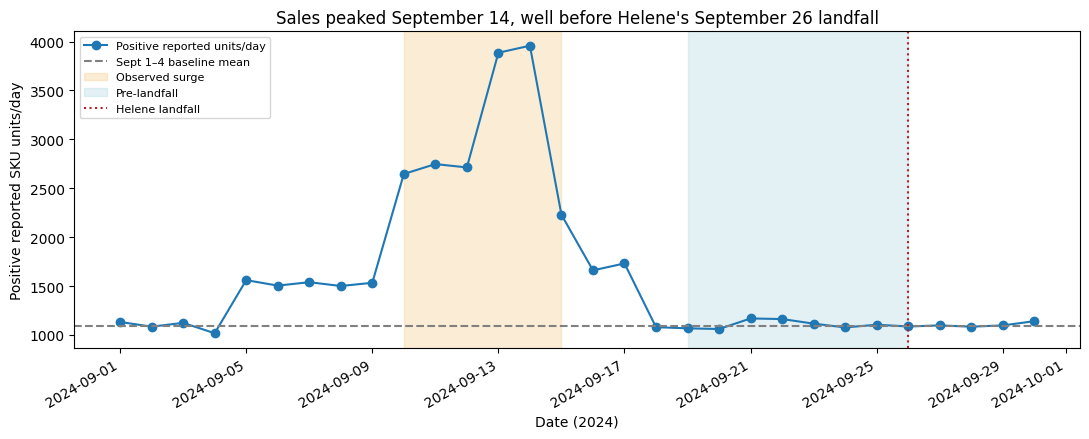

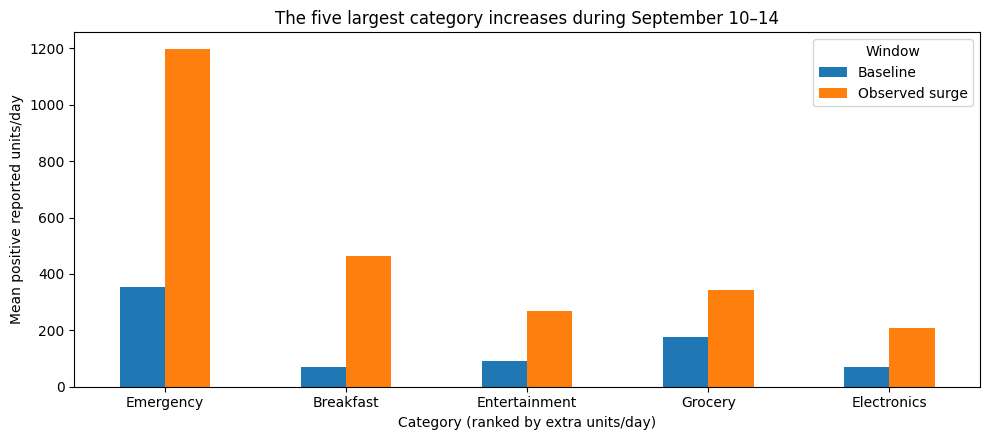

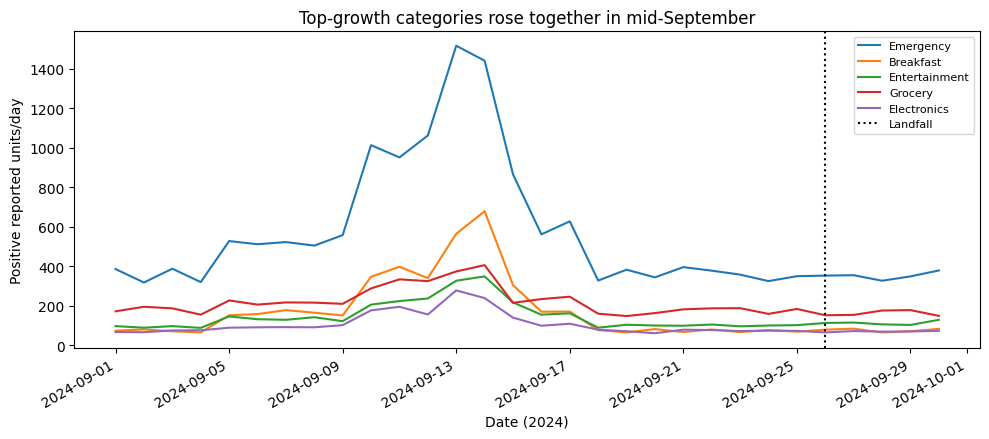

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(q1_daily.index, q1_daily, marker="o", label="Positive reported units/day")
ax.axhline(q1_base, color="gray", linestyle="--", label="Sept 1–4 baseline mean")
for label, color in [("Observed surge", "#f3b85b"), ("Pre-landfall", "#93c9d8")]:
    start, end = q1_windows[label]
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end) + pd.Timedelta(days=1), alpha=.25, color=color, label=label)
ax.axvline(pd.Timestamp("2024-09-26"), color="firebrick", linestyle=":", label="Helene landfall")
ax.set(title="Sales peaked September 14, well before Helene's September 26 landfall", xlabel="Date (2024)", ylabel="Positive reported SKU units/day")
ax.legend(fontsize=8); fig.autofmt_xdate(); fig.tight_layout(); plt.show()

ax = q1_top5[["Baseline", "Observed surge"]].plot.bar(figsize=(10, 4.5), rot=0)
ax.set(title="The five largest category increases during September 10–14", xlabel="Category (ranked by extra units/day)", ylabel="Mean positive reported units/day")
ax.legend(title="Window"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
for category in q1_top5.index:
    ax.plot(q1_categories.index, q1_categories[category], label=category)
ax.axvline(pd.Timestamp("2024-09-26"), color="black", linestyle=":", label="Landfall")
ax.set(title="Top-growth categories rose together in mid-September", xlabel="Date (2024)", ylabel="Positive reported units/day")
ax.legend(fontsize=8); fig.autofmt_xdate(); fig.tight_layout(); plt.show()

### Q1 finding

Positive reported sales averaged **1,089 units/day on September 1–4** and **3,190 on September 10–14**, a **2.93× increase in level (+192.9%)**. The peak was September 14 at 3,958 units, 12 days before landfall. In the actual September 19–25 pre-landfall week, sales averaged **1,107.4 units/day, only 1.017× baseline (+1.7%)**. Thus there is a substantial earlier spike, but little evidence of an immediate pre-landfall surge.

The five largest increases were Emergency (+844.8 units/day; 3.40×), Breakfast (+393.3; 6.50×), Entertainment (+175.85; 2.92×), Grocery (+168.15; 1.95×), and Electronics (+138.0; 2.97×). This ranking uses absolute additional units, not percentage growth. Signed net quantities give nearly the same early multiple (2.928×); using September 1–7 as the baseline lowers it to 2.492×. The spike persists, but its size depends on the baseline. Missing dates (884 rows), heterogeneous packages, and the short baseline limit interpretation. These quantities also differ from Q3's transaction-row counts. Inventory checks in Q5 are still needed before calling the pattern genuine demand.

## Q4 — Stores and geography — Nate

I compare each store's mean positive units/day in the same three Q1 windows, then divide by that store's own baseline to avoid confusing store size with growth. The transaction-to-store join must be many-to-one and preserve rows and quantities. A complete 12-store × 30-day grid includes zero-sale days.

Distance is the great-circle (haversine) distance from the provided store coordinates to the **NHC landfall point (30.0, −83.7)** cited in Q1, in kilometers. This is a proximity proxy, not distance to the full storm track or measured local wind exposure. Tallahassee (FL-619) has no coordinates in the supplied store file: it remains in the store comparison but is excluded from distance calculations rather than assigned guessed coordinates. I report both Pearson and rank correlations for the remaining stores; these are descriptive, with only 11 locations.

In [ ]:
q4_reference = stores_clean[["store_id_clean", "city", "region", "latitude", "longitude"]].copy()
assert q4_reference["store_id_clean"].is_unique
q4_joined = q1_sales.merge(q4_reference, on="store_id_clean", how="left", validate="many_to_one", indicator=True)
assert len(q4_joined) == len(q1_sales)
assert q4_joined["_merge"].eq("both").all()
assert q4_joined["quantity_clean"].sum() == q1_sales["quantity_clean"].sum()
print("Store join rows before/after:", len(q1_sales), len(q4_joined))
q4_grid = pd.MultiIndex.from_product([q4_reference["store_id_clean"], q1_days], names=["store_id_clean", "date"])
q4_daily = q4_joined.groupby(["store_id_clean", "date"])["quantity_clean"].sum().reindex(q4_grid, fill_value=0).unstack("store_id_clean")
assert q4_daily.sum().sum() == q1_daily.sum()
q4_stores = q4_reference.set_index("store_id_clean")
for label, (start, end) in q1_windows.items():
    q4_stores[label] = q4_daily.loc[start:end].mean()
assert q4_stores["Baseline"].gt(0).all()
q4_stores["surge_multiple"] = q4_stores["Observed surge"] / q4_stores["Baseline"]
q4_stores["pre_landfall_multiple"] = q4_stores["Pre-landfall"] / q4_stores["Baseline"]
lat = np.radians(pd.to_numeric(q4_stores["latitude"], errors="coerce"))
lon = np.radians(pd.to_numeric(q4_stores["longitude"], errors="coerce"))
h = np.sin((lat - np.radians(30.0))/2)**2 + np.cos(lat)*np.cos(np.radians(30.0))*np.sin((lon - np.radians(-83.7))/2)**2
q4_stores["distance_km"] = 2 * 6371.0088 * np.arcsin(np.sqrt(h.clip(0, 1)))
q4_geo = q4_stores.dropna(subset=["distance_km"])
q4_corr = pd.DataFrame([
    {"window": label, "n_stores": len(q4_geo),
     "pearson_r": q4_geo["distance_km"].corr(q4_geo[column]),
     "rank_r": q4_geo["distance_km"].rank().corr(q4_geo[column].rank())}
    for label, column in [("Observed surge", "surge_multiple"), ("Pre-landfall", "pre_landfall_multiple")]
]).set_index("window")
display(q4_stores.sort_values("distance_km").round(3))
display(q4_corr.round(3))
print("Stores excluded from distance analysis:", q4_stores.loc[q4_stores.distance_km.isna(), "city"].tolist())

Store join rows before/after: 24521 24521


,city,region,latitude,longitude,Baseline,Observed surge,Pre-landfall,surge_multiple,pre_landfall_multiple,distance_km
store_id_clean,,,,,,,,,,
FL-078,Gainesville,North,29.652,-82.325,97.50,256.2,89.429,2.628,0.917,138.200
FL-412,Jacksonville,North,30.332,-81.656,82.75,262.8,91.286,3.176,1.103,199.969
FL-105,Tampa,West,27.951,-82.457,91.50,278.6,91.714,3.045,1.002,257.960
FL-445,St. Petersburg,West,27.768,-82.640,97.75,272.8,97.000,2.791,0.992,268.815
FL-156,Daytona Beach,East,29.211,-81.023,94.25,268.8,95.571,2.852,1.014,273.290
FL-302,Lakeland,Central,28.040,-81.950,97.75,286.0,93.571,2.926,0.957,276.547
FL-239,Orlando,Central,28.538,-81.379,89.50,245.2,91.143,2.740,1.018,277.646
FL-287,Kissimmee,Central,28.292,-81.408,90.00,256.2,97.571,2.847,1.084,292.617
FL-710,Pensacola,Panhandle,30.421,-87.217,86.25,268.2,92.000,3.110,1.067,341.165


,n_stores,pearson_r,rank_r
window,,,
Observed surge,11,0.430,0.227
Pre-landfall,11,0.077,0.200


Stores excluded from distance analysis: ['Tallahassee']


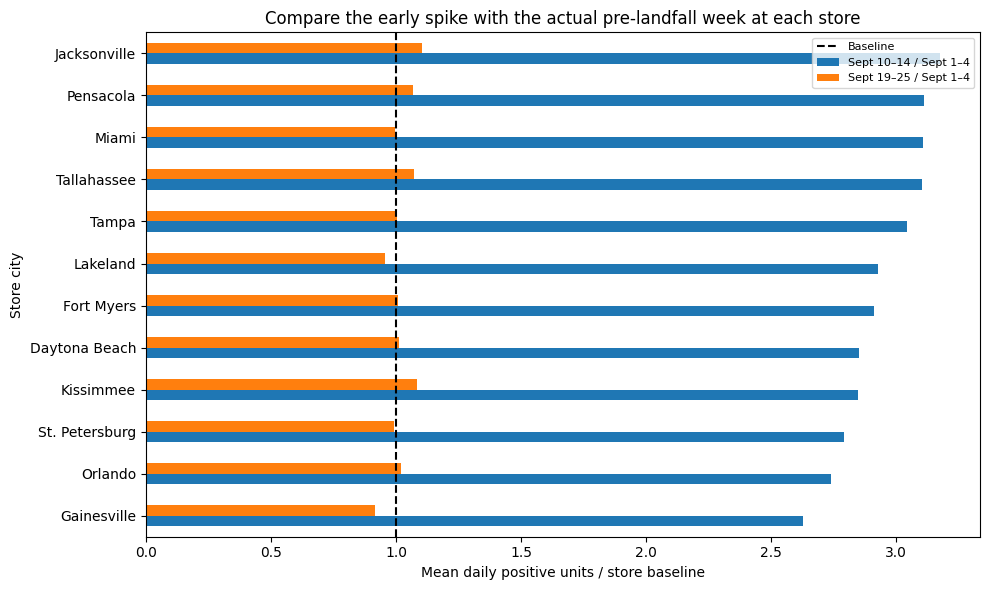

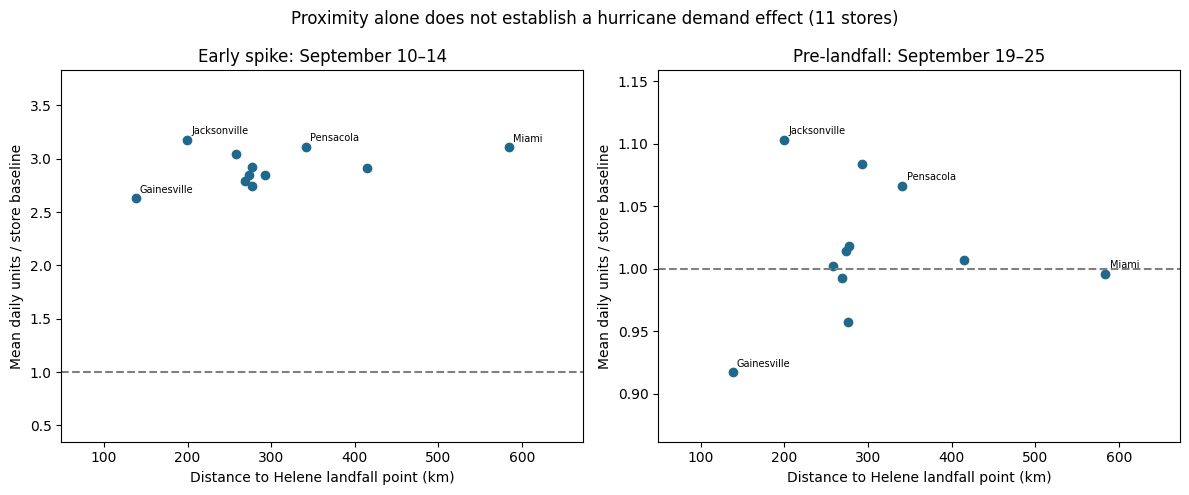

In [ ]:
q4_plot = q4_stores.set_index("city")[["surge_multiple", "pre_landfall_multiple"]].sort_values("surge_multiple")
ax = q4_plot.rename(columns={"surge_multiple": "Sept 10–14 / Sept 1–4", "pre_landfall_multiple": "Sept 19–25 / Sept 1–4"}).plot.barh(figsize=(10, 6))
ax.axvline(1, color="black", linestyle="--", label="Baseline")
ax.set(title="Compare the early spike with the actual pre-landfall week at each store", xlabel="Mean daily positive units / store baseline", ylabel="Store city")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, column, title in zip(axes, ["surge_multiple", "pre_landfall_multiple"], ["Early spike: September 10–14", "Pre-landfall: September 19–25"]):
    ax.scatter(q4_geo["distance_km"], q4_geo[column], color="#21688D")
    # Label selected reference stores to keep the crowded middle readable.
    for store, row in q4_geo.loc[["FL-078", "FL-412", "FL-710", "FL-330"]].iterrows():
        ax.annotate(row["city"], (row["distance_km"], row[column]), fontsize=7, xytext=(3, 4), textcoords="offset points")
    ax.axhline(1, color="gray", linestyle="--")
    ax.set(title=title, xlabel="Distance to Helene landfall point (km)", ylabel="Mean daily units / store baseline")
    ax.margins(x=.2, y=.3)
fig.suptitle("Proximity alone does not establish a hurricane demand effect (11 stores)")
fig.tight_layout(); plt.show()

### Q4 finding

All 12 stores share the early spike: September 10–14 averages range from **2.63× baseline in Gainesville to 3.18× in Jacksonville**. The actual September 19–25 pre-landfall ratios are much smaller, **0.92×–1.10×**. The validated store join preserves all **24,521 dated positive-quantity rows** and their total units.

Among 11 stores with coordinates, distance versus early-spike growth has **Pearson r = +0.430** (rank correlation +0.227); distance versus pre-landfall growth has **r = +0.077** (rank correlation +0.200). These results do not support a pattern of larger increases nearer landfall: that would require a negative association. Gainesville, the closest measured store (138 km), has a smaller early ratio than Miami, the farthest (584 km; 3.11×).

This is a descriptive comparison, not a causal or significance claim. Tallahassee's missing coordinates remove a potentially important nearby store, landfall distance does not measure local weather or the full track, and there are only 11 usable locations. The early spike is geographically broad and predates landfall by almost two weeks. For planning, do not allocate extra stock solely using distance or this historical spike; combine local forecasts with Q5's inventory checks.